# Does the temporal insertion depletion survive matching SNPs on ecotype-of-origin climate?

`temporal_s_consolidated.ipynb` reports that SVs — insertions in particular — are more purged at
hot/arid gardens: the per-site de-trended shift in `s` correlates with garden climate at
ρ ≈ −0.48 (bio1) and +0.65 (bio18). That shift is measured against SNPs **matched on starting
frequency $p_0$**.

**The confound.** Pool AF is a global-mode founder projection, so when a garden's ecotype
composition shifts — warm-origin ecotypes winning at hot gardens — *every* variant carried
preferentially by cold-origin ecotypes falls, with no selection on it at all. And insertion alleles
are carried slightly more often by cold-origin ecotypes: per-founder count ρ = −0.36 with origin
bio1, and the carrier-origin mean is 9.36 °C for insertions against 9.60 °C for SNPs.

Frequency matching cannot remove this. Two variants at the same $p_0$ can sit on completely
different ecotype backgrounds, and it is the background that garden turnover acts on.

**The fix.** Match the SNP comparison set on **both $p_0$ and carrier-origin climate**, so the
SV-vs-SNP contrast is taken between variants carried by ecotypes of the same origin climate.
`carrier_bio1` = mean origin bio1 of the founders carrying the variant, computed from the founder
panel for SVs and SNPs alike. Bins are a joint 5 × 5 grid ($p_0$ × carrier climate) against the
10 $p_0$ bins of the published de-trending; cells with < 20 variants on either side are dropped.

**Read the control first.** The $p_0$-only shift is recomputed in the same run on the same variant
set. If it does not land on the published ρ, the matched number means nothing.

In [1]:

import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib as mpl
from scipy import stats
plt.rcParams.update({'figure.dpi':110,'font.size':8,'axes.linewidth':0.6})

G=os.path.abspath(os.path.join(os.getcwd(),"..","r1_sv_negative_selection","results","sv_adaptive"))
os.makedirs(f"{G}/plots",exist_ok=True)
TAG="_event2"      # Truvari events (SV_UNIT=event, SV_MIN_MAC=2); alleles are no longer the unit -- see other _event2 notebooks
def style(ax):
    ax.set_axisbelow(True); ax.grid(color="0.88",lw=0.7)
    for sp in ax.spines.values(): sp.set_visible(False)

D=pd.read_csv(f"{G}/sv_temporal_climate_matched_sites{TAG}.csv")
S=pd.read_csv(f"{G}/sv_temporal_climate_matched_summary{TAG}.csv").set_index("measure")
COL={"p0only":"#D55E00","matched":"#0072B2"}
LAB={"p0only":"matched on $p_0$ only","matched":"matched on $p_0$ + carrier-origin climate"}
print(f"{len(D)} gardens; bio1 {D.bio1.min():.1f}-{D.bio1.max():.1f} C, bio18 {D.bio18.min():.0f}-{D.bio18.max():.0f} mm")


31 gardens; bio1 6.0-21.6 C, bio18 1-610 mm


## 1. Control — does the $p_0$-only recomputation land on the old allele-level published result?

Old (allele-level, MIN_MAC=12): ρ ≈ −0.48 (bio1) / +0.65 (bio18) for all SVs; ≈ −0.39 / +0.73 for
insertions. Shown for **context, not as a pass/fail gate** — the unit here is now the Truvari event
(alleles of one bubble collapsed by sequence similarity, `_event2` = SV_MIN_MAC=2), so an exact
reproduction is not expected on its own. A large deviation is itself the finding; see §5/"Reading it".

In [2]:

pub={"sv_p0only":(-0.48,0.65),"ins_p0only":(-0.39,0.73)}
print(f"{'measure':<14}{'rho bio1':>10}{'old allele':>11}{'rho bio18':>12}{'old allele':>11}")
for m,(p1,p18) in pub.items():
    r=S.loc[m]
    print(f"{m:<14}{r.rho_bio1:>10.3f}{p1:>11.2f}{r.rho_bio18:>12.3f}{p18:>11.2f}")
print("\n(comparison only -- events are a different, more conservative unit than alleles; "
      "see \"Reading it\" for what this deviation means)")


measure         rho bio1 old allele   rho bio18 old allele
sv_p0only          0.171      -0.48      -0.492       0.65
ins_p0only        -0.198      -0.39       0.227       0.73

(comparison only -- events are a different, more conservative unit than alleles; see "Reading it" for what this deviation means)


## 2. The trend, before and after matching on carrier-origin climate

Each point is a garden: x = its climate, y = the de-trended shift in `s` for insertion alleles
(below 0 = insertions more purged than the matched SNP set). Left = $p_0$-only matching (the
published de-trending), right = $p_0$ + carrier-origin climate. Top row temperature, bottom row
precipitation of the warmest quarter.

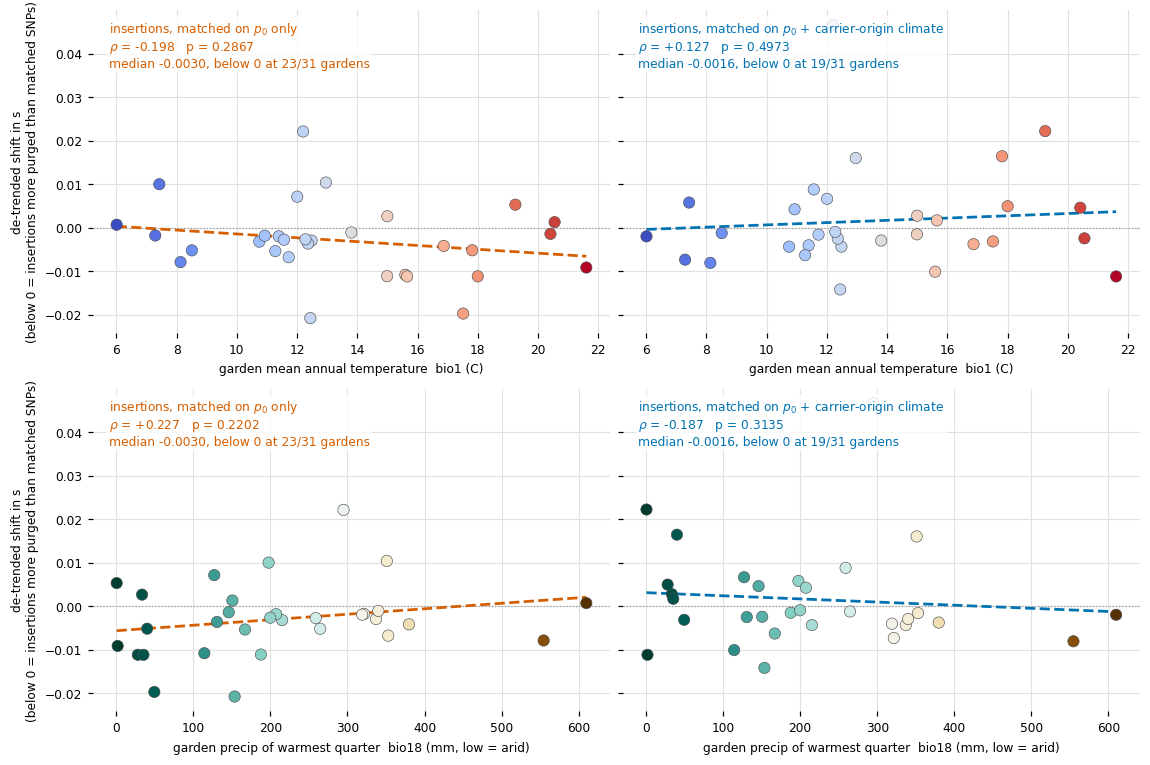

In [3]:

fig,ax=plt.subplots(2,2,figsize=(10.5,7),sharey="row")
for i,(cv,clab,cmap) in enumerate([("bio1","garden mean annual temperature  bio1 (C)","coolwarm"),
                                   ("bio18","garden precip of warmest quarter  bio18 (mm, low = arid)","BrBG_r")]):
    for j,tag in enumerate(("p0only","matched")):
        a=ax[i,j]; style(a); col=f"ins_{tag}"
        d=D[[cv,col]].dropna()
        a.axhline(0,color="0.6",lw=0.8,ls=":")
        a.scatter(d[cv],d[col],c=d[cv],cmap=cmap,s=55,zorder=3,edgecolor="0.3",linewidth=0.4)
        b,a0=np.polyfit(d[cv],d[col],1); xs=np.array([d[cv].min(),d[cv].max()])
        a.plot(xs,a0+b*xs,color=COL[tag],lw=1.8,ls="--")
        r=stats.spearmanr(d[cv],d[col])
        a.annotate(f"insertions, {LAB[tag]}\n"+r"$\rho$"+f" = {r.statistic:+.3f}   p = {r.pvalue:.4f}\n"
                   f"median {d[col].median():+.4f}, below 0 at {int((d[col]<0).sum())}/{len(d)} gardens",
                   xy=(0.03,0.97),xycoords="axes fraction",va="top",fontsize=8,color=COL[tag],
                   bbox=dict(facecolor="white",alpha=0.8,edgecolor="none",pad=1.5))
        a.set_xlabel(clab)
        if j==0: a.set_ylabel("de-trended shift in s\n(below 0 = insertions more purged than matched SNPs)")
fig.tight_layout(); fig.savefig(f"{G}/plots/sv_temporal_climate_matched.png",dpi=130,bbox_inches="tight"); plt.show()


## 3. The same gardens under both matchings

x = the garden's shift with $p_0$-only matching, y = with carrier-climate matching, coloured by
garden temperature. On the dotted 1:1 line the control changed nothing. A cloud collapsed onto y = 0
would mean the signal was carrier climate; a cloud along the diagonal with slope < 1 means the
magnitude shrinks but the ordering survives.

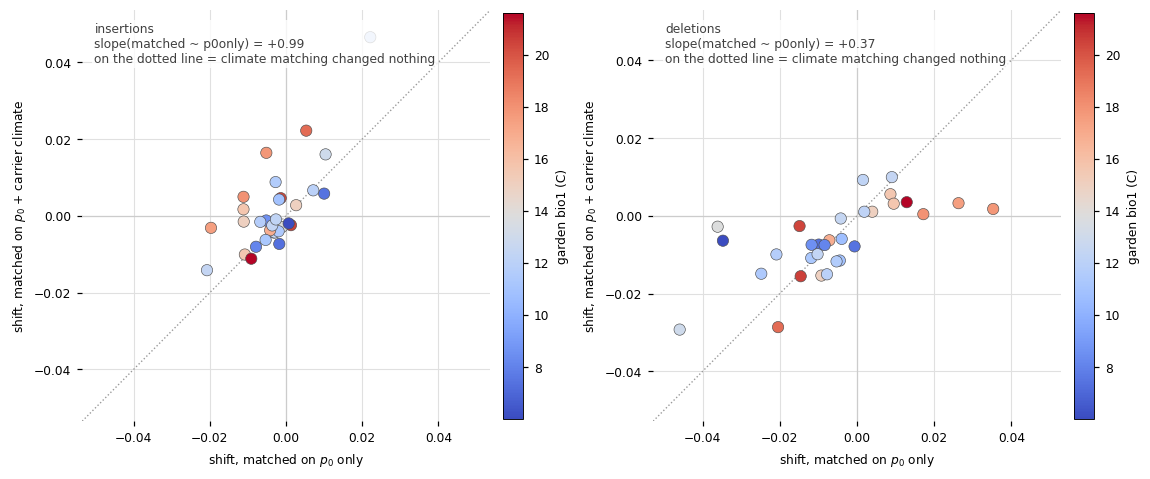

In [4]:

fig,ax=plt.subplots(1,2,figsize=(10.5,4.4))
for a,cls,lab in zip(ax,("ins","del"),("insertions","deletions")):
    style(a); d=D[["bio1",f"{cls}_p0only",f"{cls}_matched"]].dropna()
    lim=np.abs(np.r_[d[f"{cls}_p0only"],d[f"{cls}_matched"]]).max()*1.15
    a.axhline(0,color="0.8",lw=0.8); a.axvline(0,color="0.8",lw=0.8)
    a.plot([-lim,lim],[-lim,lim],color="0.6",lw=0.9,ls=":")
    sc=a.scatter(d[f"{cls}_p0only"],d[f"{cls}_matched"],c=d.bio1,cmap="coolwarm",s=55,zorder=3,
                 edgecolor="0.3",linewidth=0.4)
    a.set_xlim(-lim,lim); a.set_ylim(-lim,lim)
    sl=np.polyfit(d[f"{cls}_p0only"],d[f"{cls}_matched"],1)[0]
    a.annotate(f"{lab}\nslope(matched ~ p0only) = {sl:+.2f}\n"
               f"on the dotted line = climate matching changed nothing",
               xy=(0.03,0.97),xycoords="axes fraction",va="top",fontsize=8,color="0.25",
               bbox=dict(facecolor="white",alpha=0.8,edgecolor="none",pad=1.5))
    a.set_xlabel("shift, matched on $p_0$ only"); a.set_ylabel("shift, matched on $p_0$ + carrier climate")
    plt.colorbar(sc,ax=a,label="garden bio1 (C)",fraction=0.046,pad=0.03)
fig.tight_layout(); fig.savefig(f"{G}/plots/sv_temporal_climate_matched_paired.png",dpi=130,bbox_inches="tight"); plt.show()


## 4. Per-site grid, both matchings

**Six grids: all SVs pooled (as in the published figure), then insertions and deletions separately,
each de-trended both ways.** The pooled version is the direct counterpart of
`temporal_s_consolidated`; the split versions matter because the two classes behave differently and
deletions dilute the pooled signal. Built twice per class: SNPs matched on
**$p_0$ only** and against SNPs matched on **$p_0$ + carrier-origin climate**. Sites ordered
cold → hot; orange is SVs, blue is short indels, and the SNP line is 0 by construction.

**Construction.** Each variant's residual is its `s` minus the median `s` of the SNPs **in its own
cell**; the curve is the rolling median of those residuals against $p_0$. Both versions use the same
10 $p_0$ bins, and the matched one adds 5 carrier-climate bins on top (50 cells), so the only
difference between the two grids is the climate dimension. Cells with fewer than 20 SNPs are dropped.

This differs slightly from the published grid, which de-trends against a smooth rolling SNP curve
over $p_0$ rather than binned cells — necessary here because with 2D matching the baseline is no
longer a function of $p_0$ alone.

**The y-axis is shared between the two matchings within a class**, so attenuation is visible rather
than hidden by autoscaling. It is *not* shared between insertions and deletions, whose magnitudes
differ several-fold.

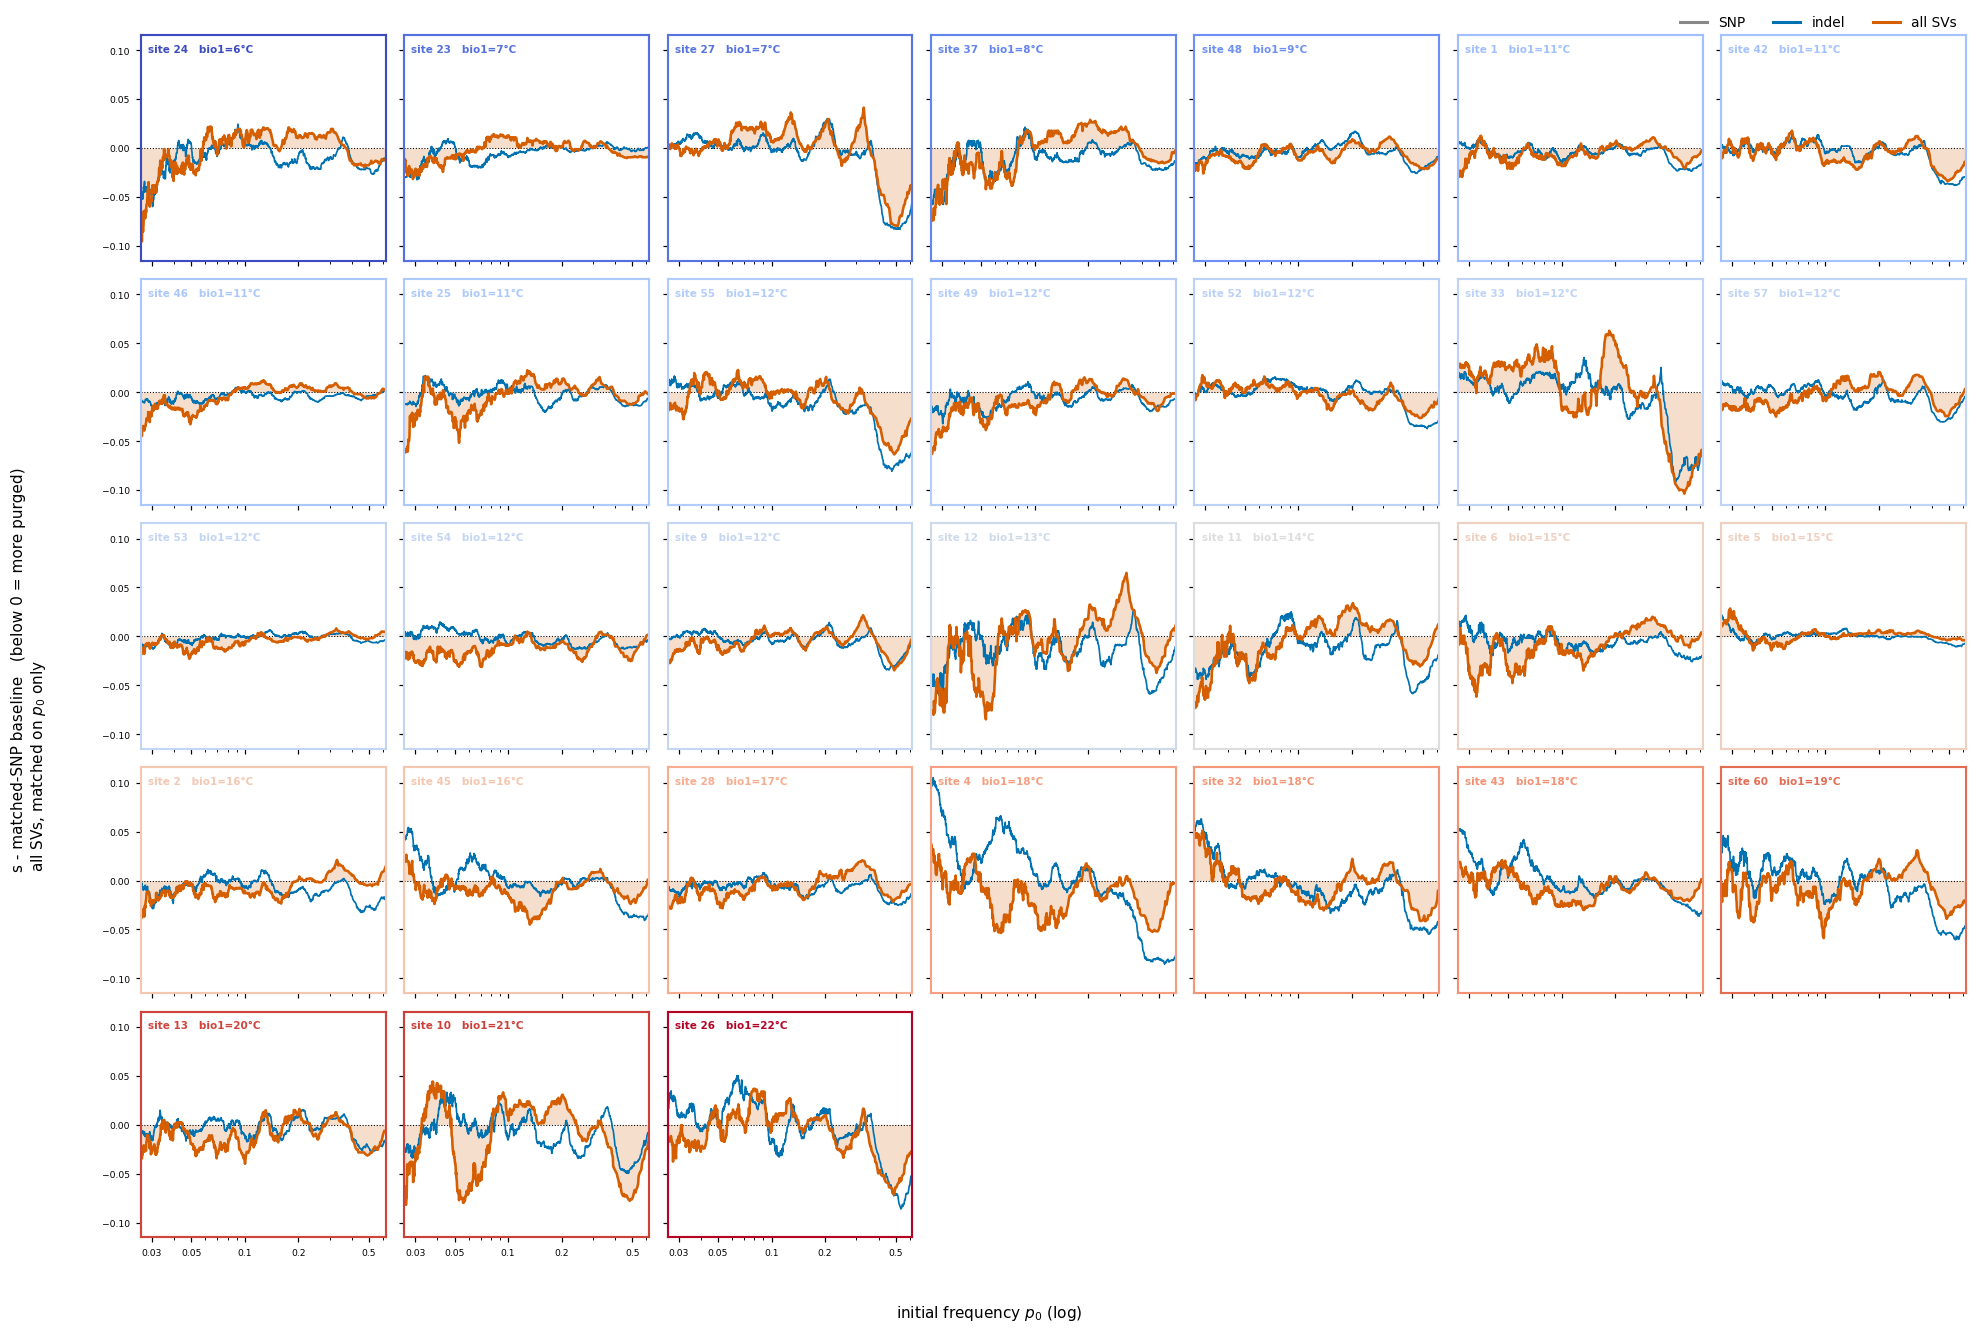

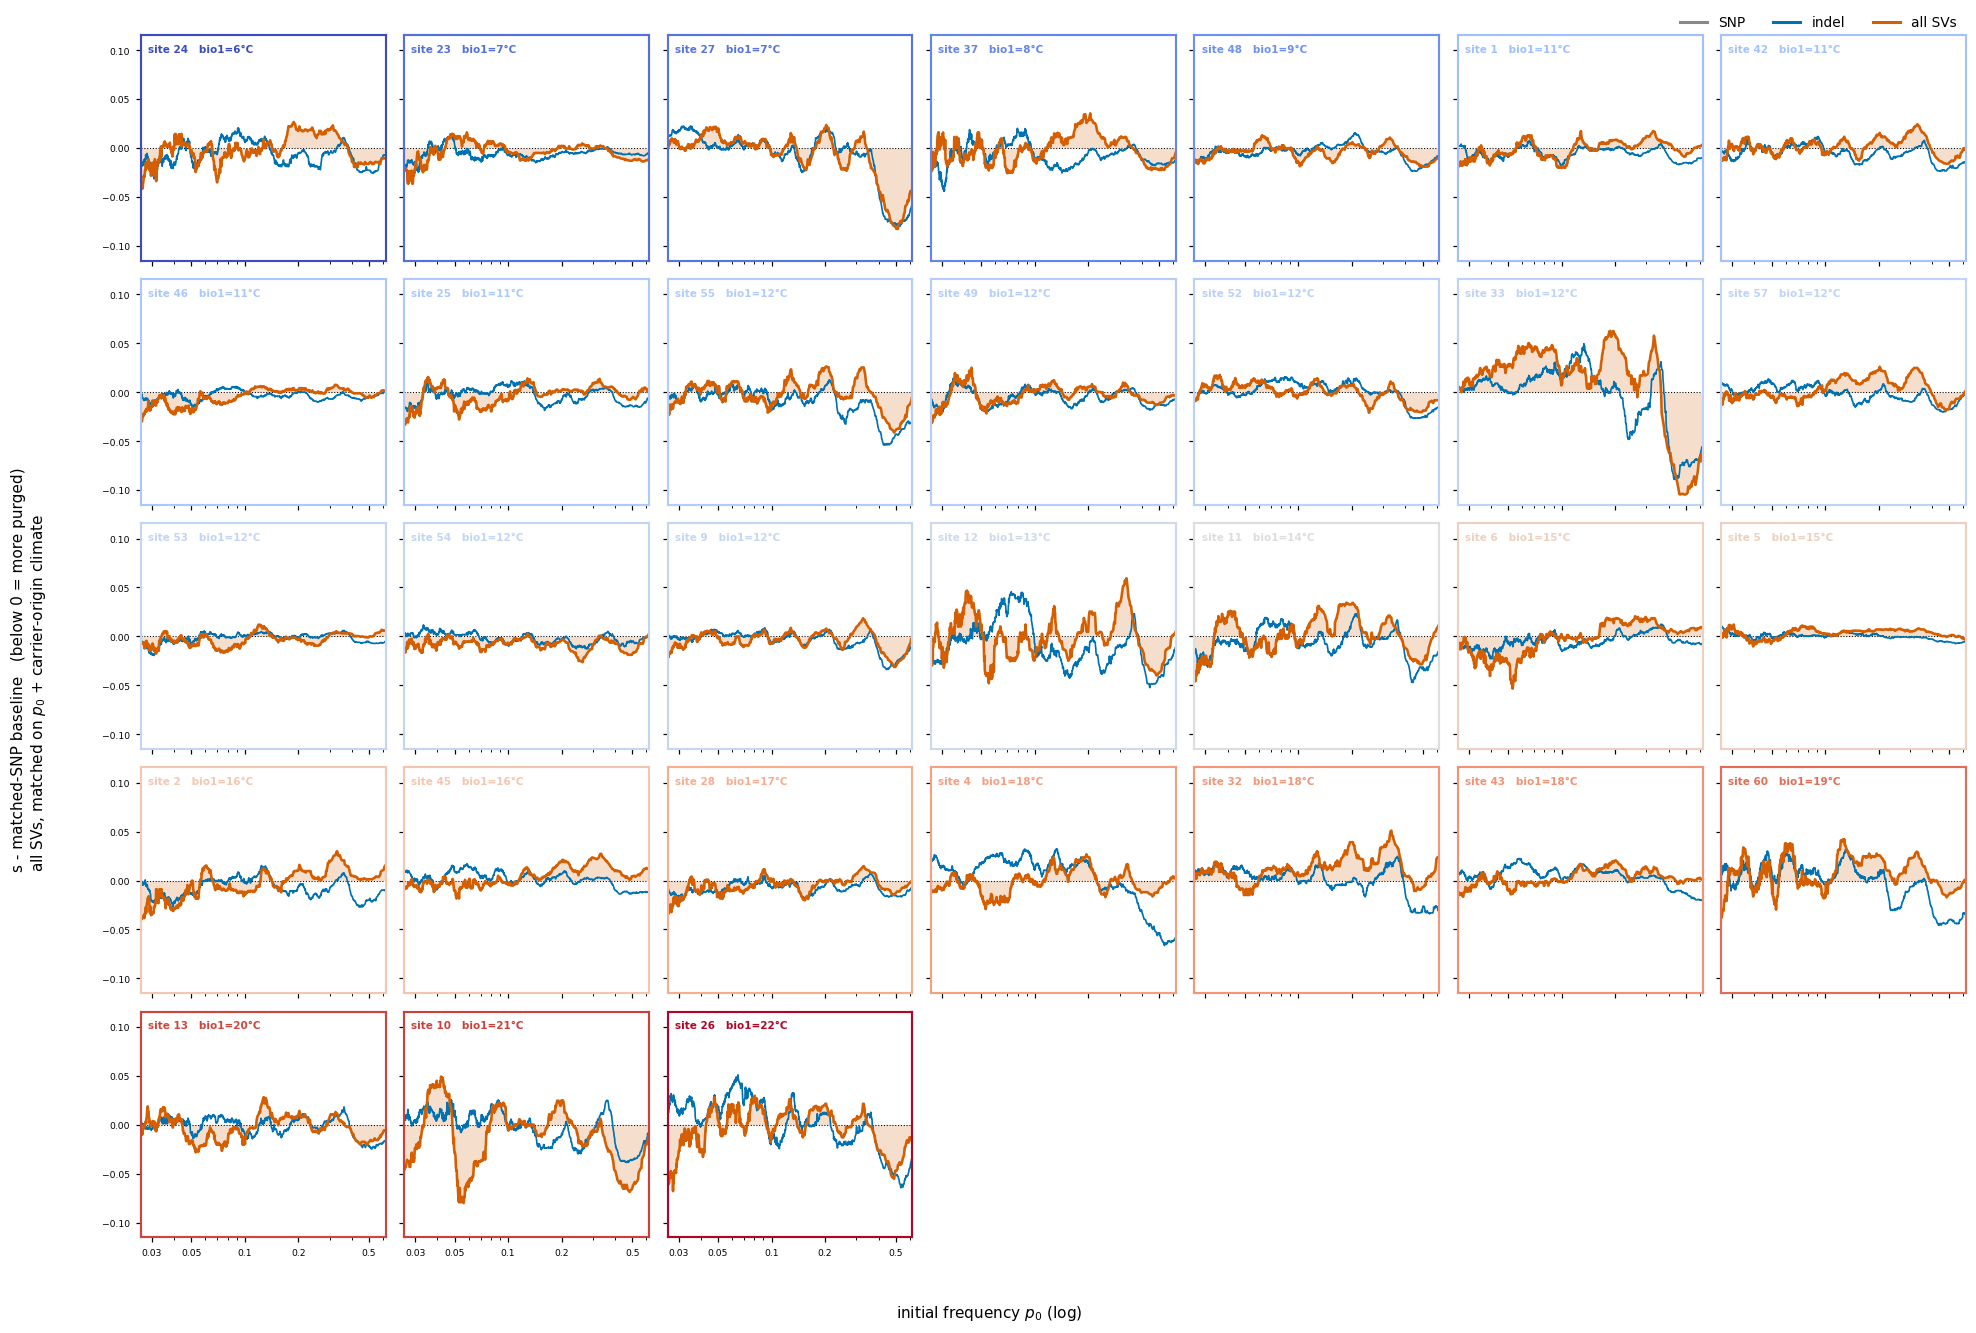

all SVs: shared ylim -0.115 to +0.116


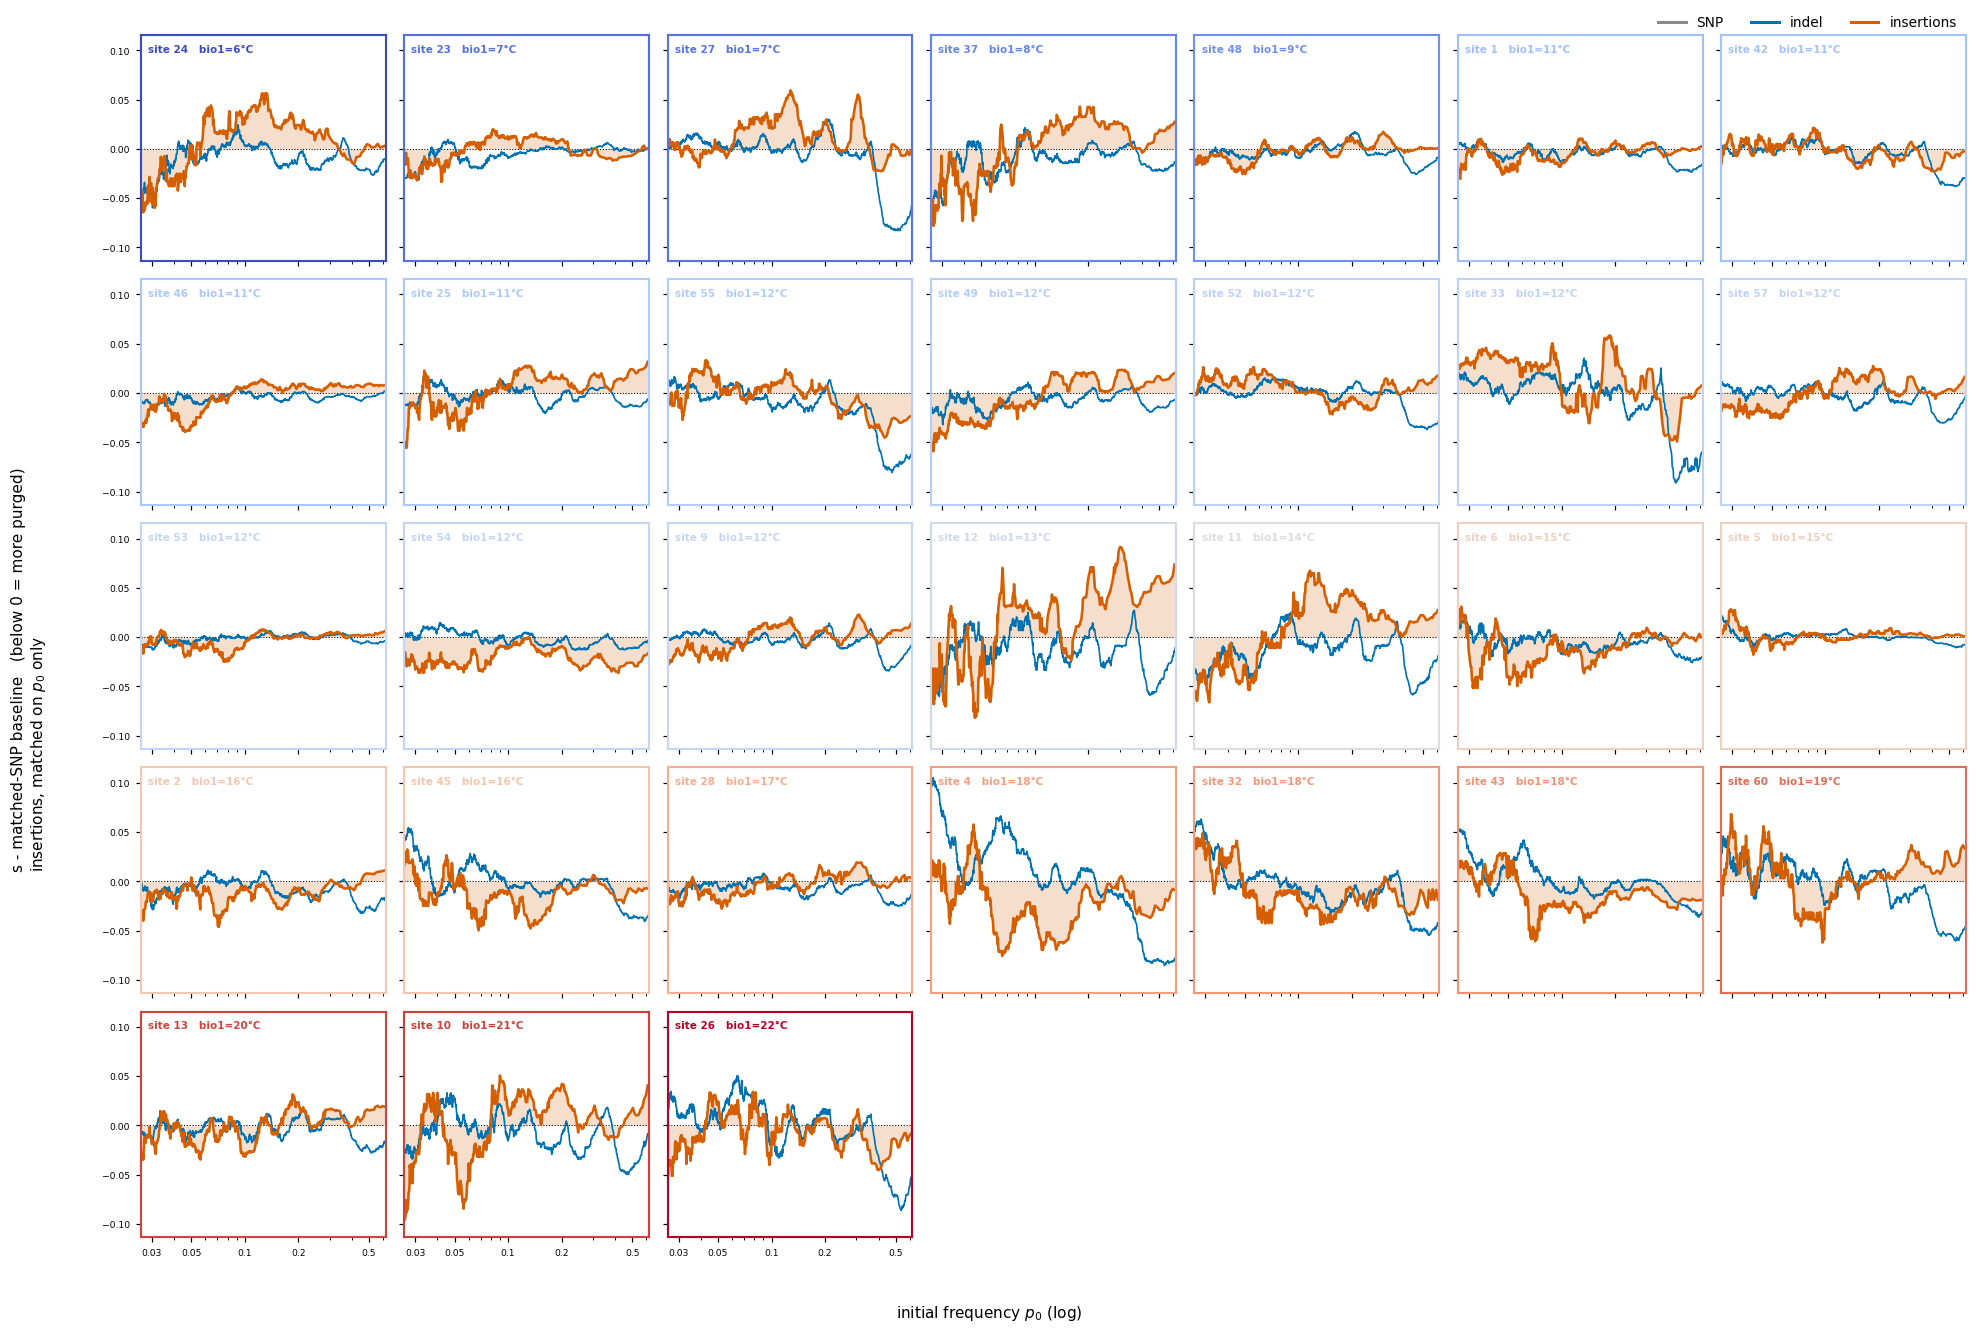

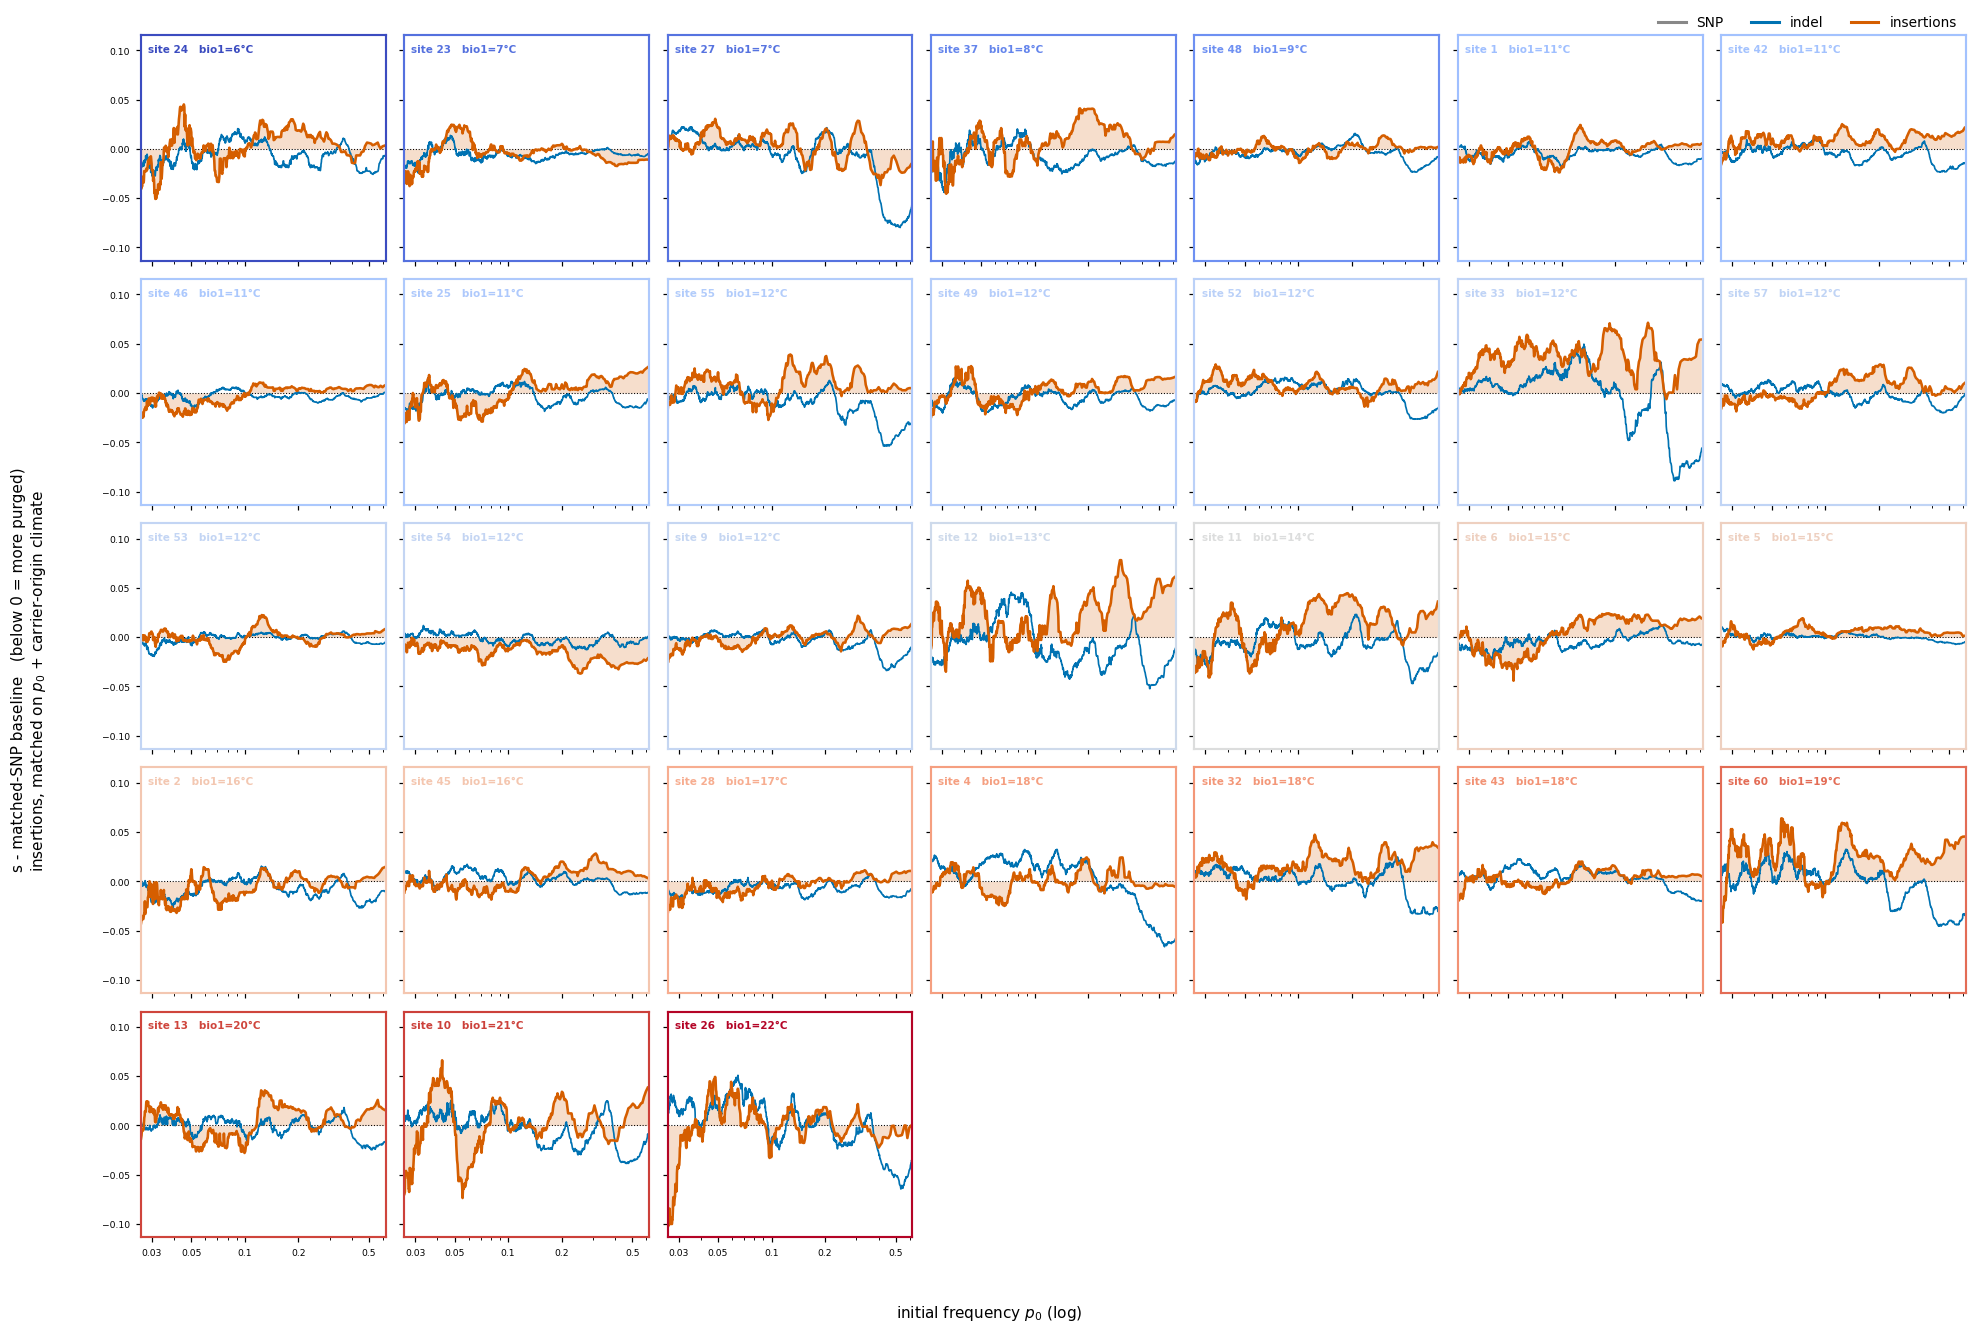

insertions: shared ylim -0.113 to +0.116


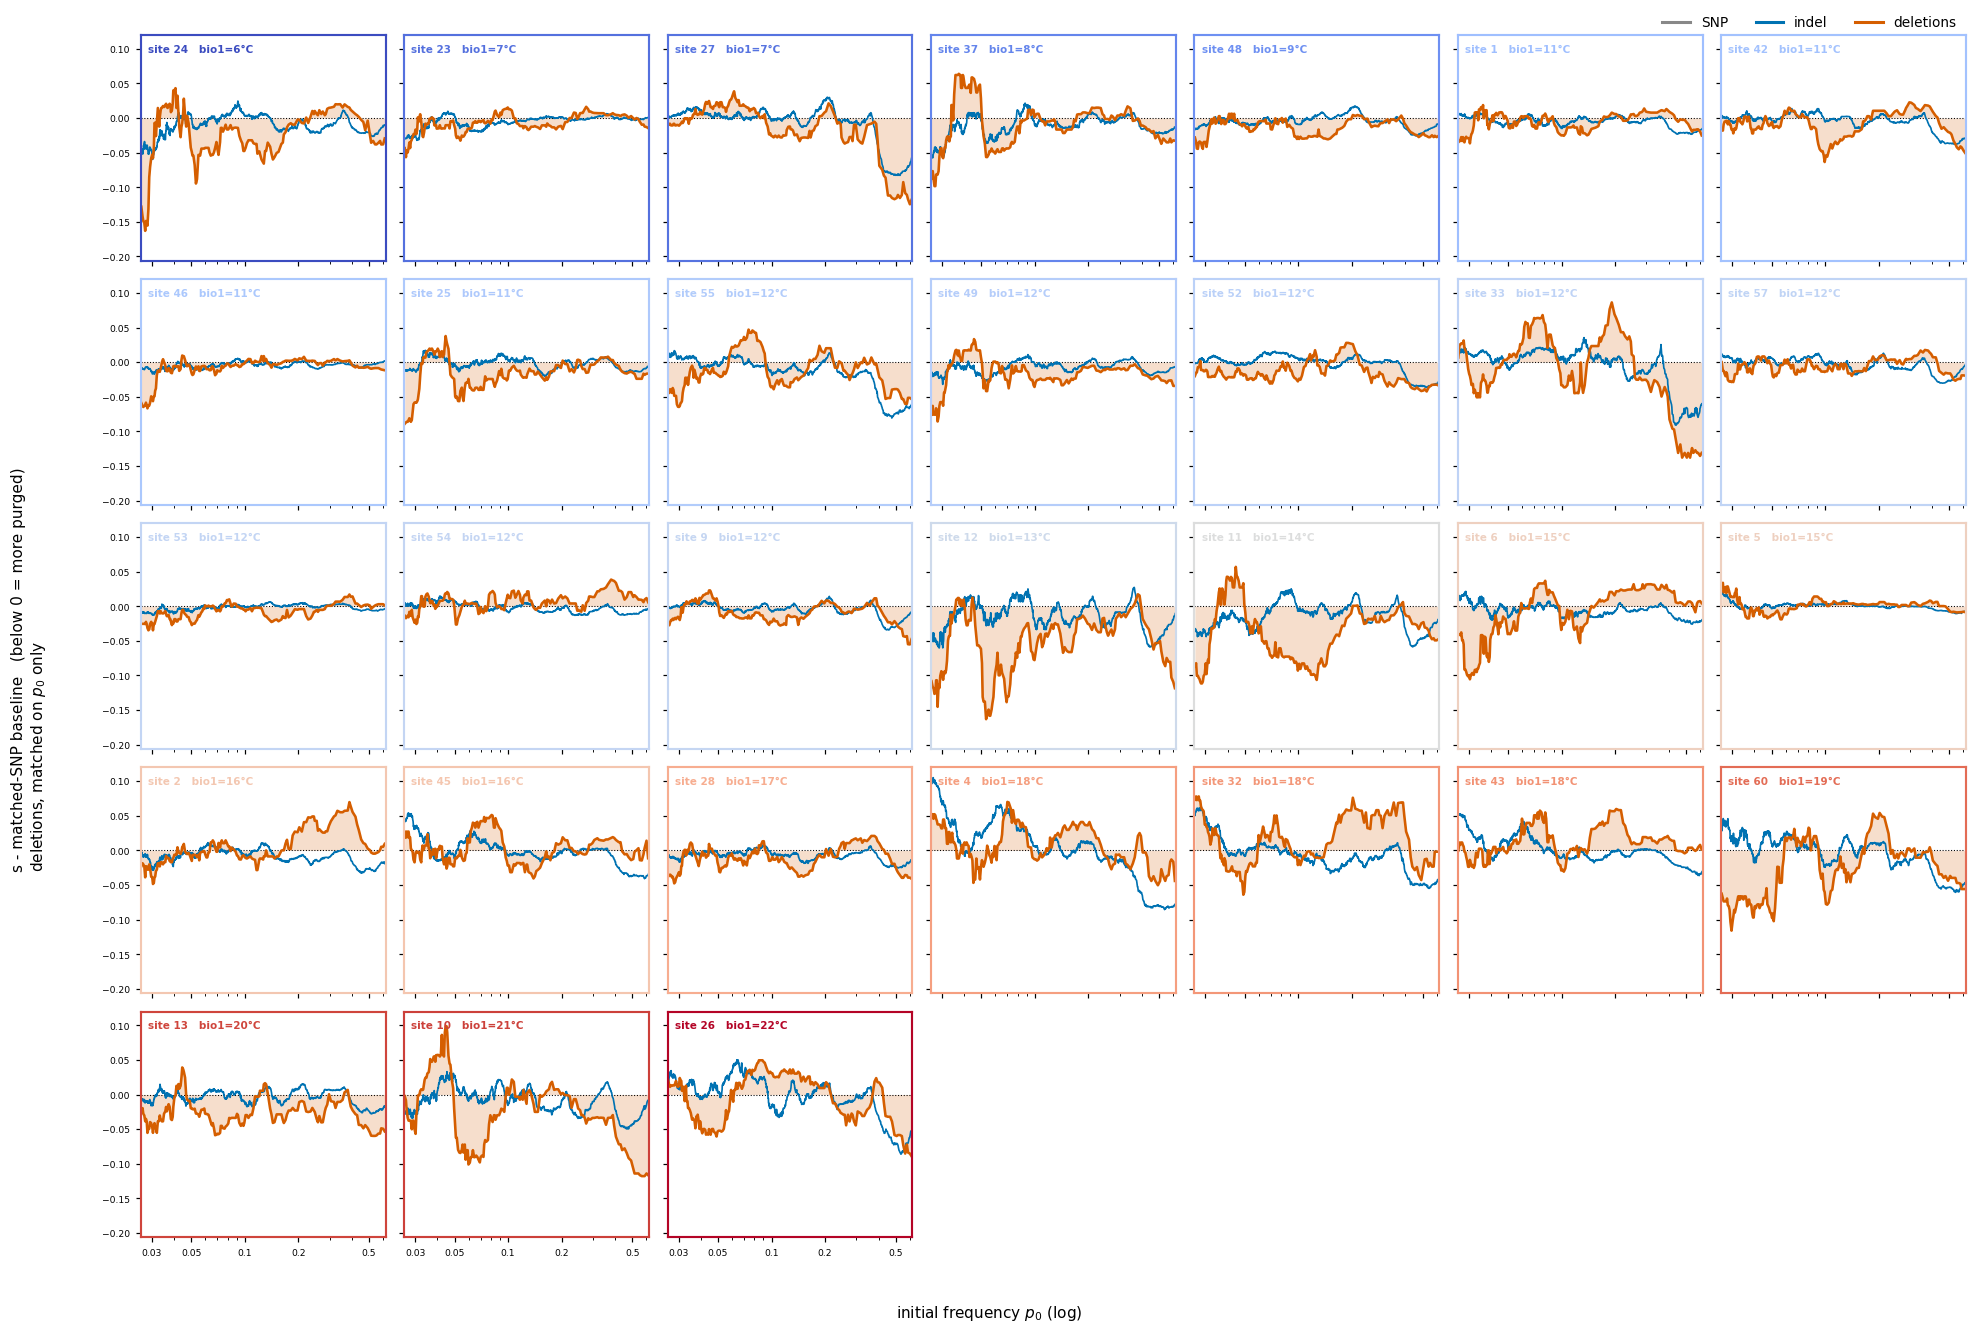

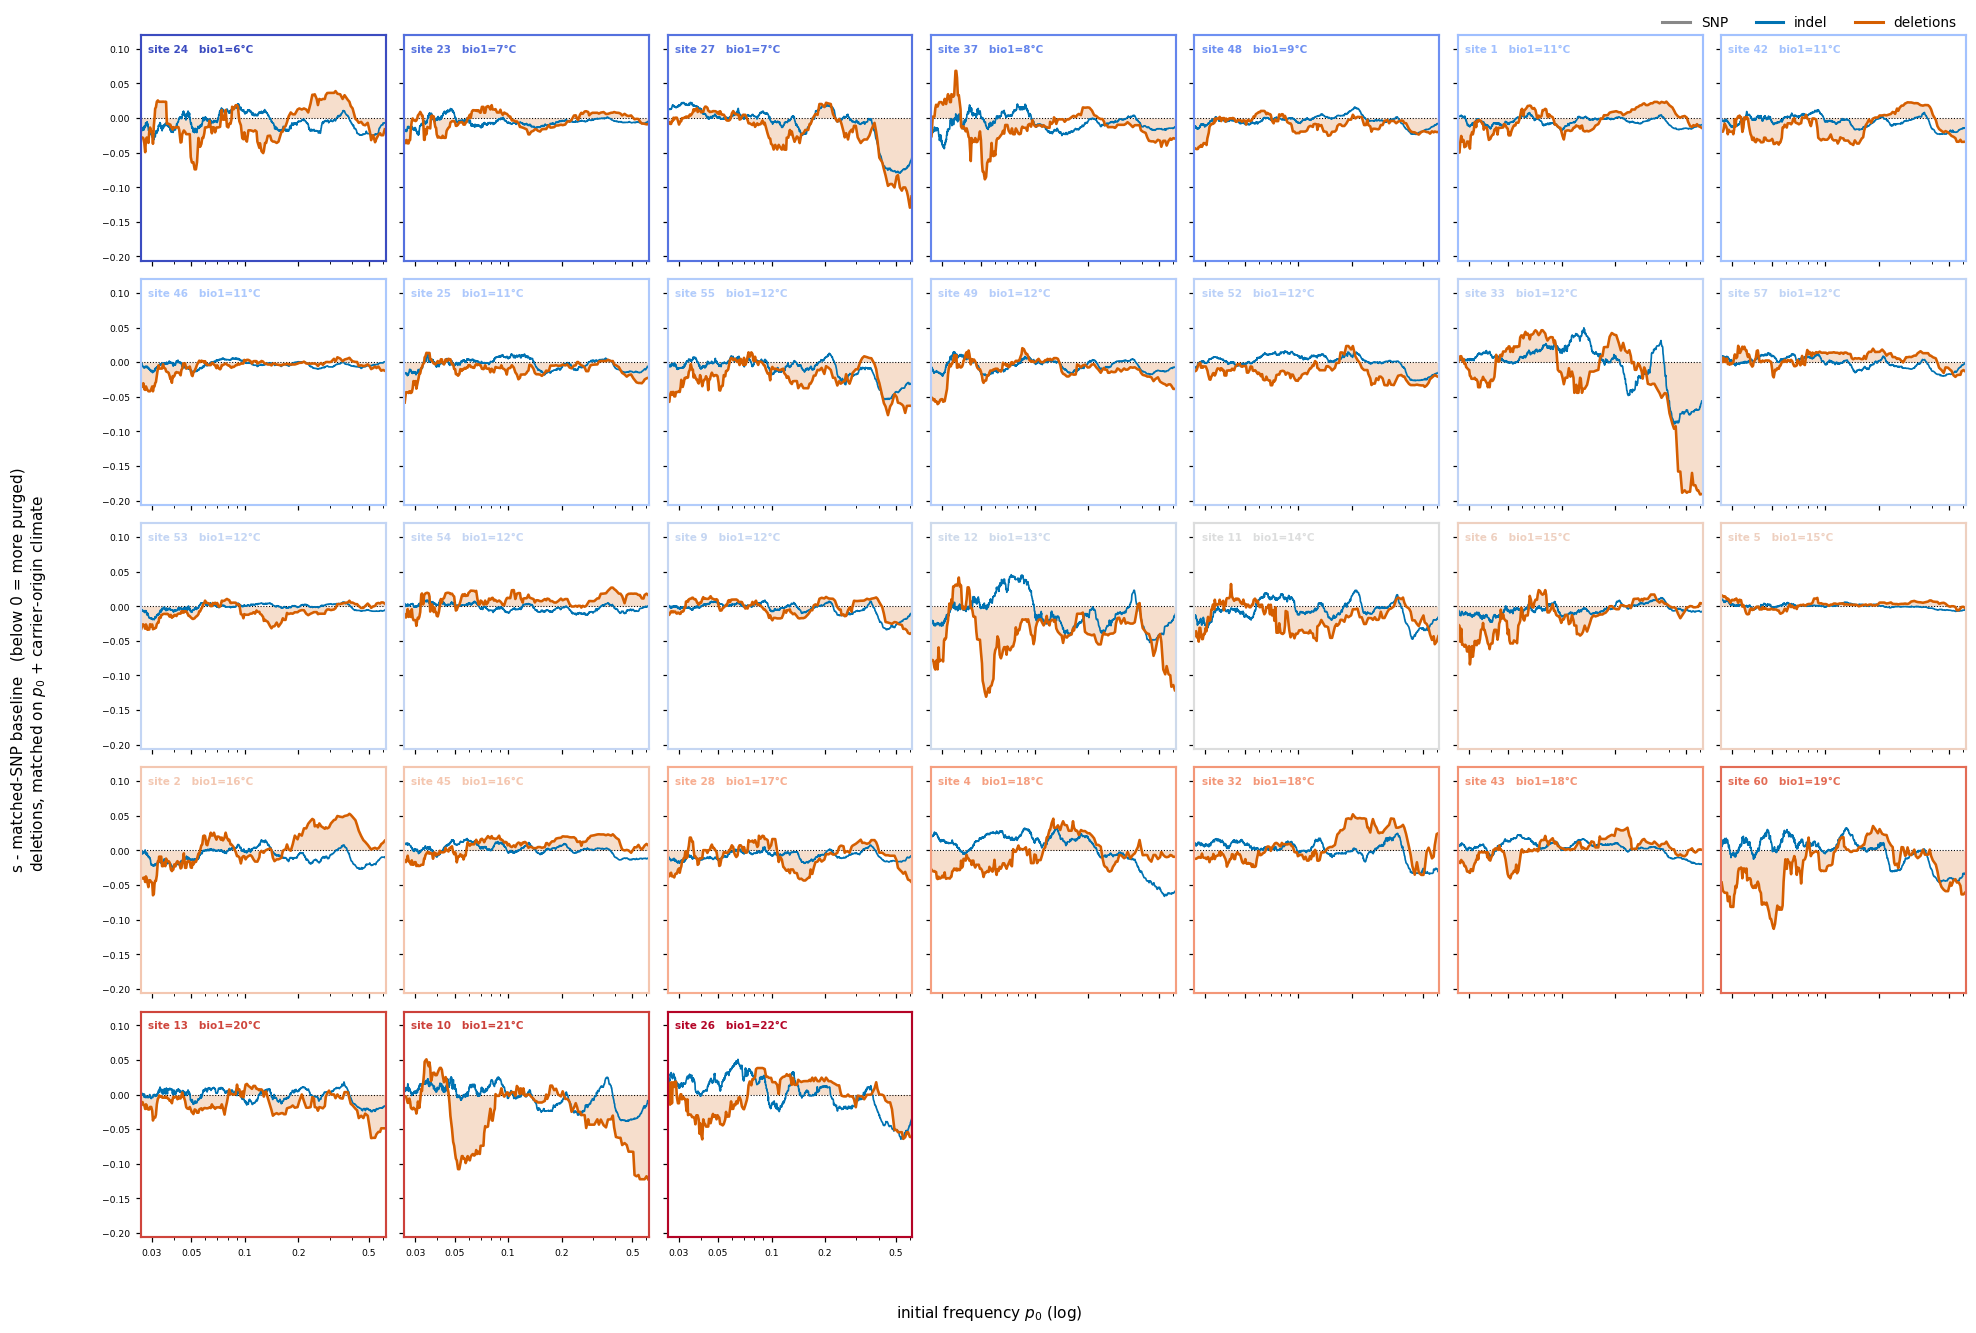

deletions: shared ylim -0.206 to +0.120

class       matching       area below 0 vs garden bio1         p
all SVs     p0only                              -0.501    0.0041
all SVs     matched                             -0.019    0.9194
insertions  p0only                              -0.472    0.0074
insertions  matched                             -0.028    0.8819
deletions   p0only                              -0.020    0.9143
deletions   matched                             +0.008    0.9639


In [5]:

from matplotlib.lines import Line2D
P=np.load(f"{G}/sv_temporal_climate_matched_persite{TAG}.npz")
COL={"SNP":"#888888","indel":"#0072B2","SV":"#D55E00"}
XTICKS=[0.03,0.05,0.1,0.2,0.5]; XLIM=(0.026,0.62)
meta=D.sort_values("bio1").reset_index(drop=True); sites=meta.site.tolist()

def rolling_curve(res,p0,thin=15):
    m=~np.isnan(res); res,p0=res[m],p0[m]
    o=np.argsort(p0); p0s,ss=p0[o],res[o]
    win=max(51,len(ss)//8); win+=1-win%2
    med=pd.Series(ss).rolling(win,center=True,min_periods=win//3).median().to_numpy()
    return p0s[::thin],med[::thin]

def _vis(x,y):
    m=(x>=XLIM[0])&(x<=XLIM[1]); return x[m],y[m]

# one curve set per (class, matching); "indel" is the shared reference line in every grid
CUR={}
for tag in ("p0only","matched"):
    for key in ("sv","ins","del","indel"):
        CUR[(tag,key)]={s_:_vis(*rolling_curve(P[f"{s_}_res_{key}_{tag}"],P[f"p0_{key}"])) for s_ in sites}

def ylim_for(key):
    # shared between the two matchings WITHIN a class, so p0-only and matched are comparable;
    # not shared between insertions and deletions, whose magnitudes differ several-fold
    v=np.concatenate([CUR[(t,k)][s_][1] for t in ("p0only","matched") for k in (key,"indel") for s_ in sites])
    pad=0.05*(v.max()-v.min()); return (v.min()-pad,v.max()+pad)

def draw_grid(tag,key,klab,fname):
    YLIM=ylim_for(key)
    ncol=7; nrow=int(np.ceil(len(sites)/ncol))
    norm=mpl.colors.Normalize(vmin=meta.bio1.min(),vmax=meta.bio1.max()); cmap=mpl.cm.coolwarm
    fig,axes=plt.subplots(nrow,ncol,figsize=(18,2.4*nrow),sharex=True,sharey=True)
    axes=axes.ravel()
    for ax in axes[len(sites):]: ax.axis("off")
    for i,s_ in enumerate(sites):
        ax=axes[i]; cv=CUR[(tag,key)][s_]; ci=CUR[(tag,"indel")][s_]
        ax.axhline(0,color="k",lw=0.7,ls=":")
        ax.fill_between(cv[0],0,cv[1],color=COL["SV"],alpha=0.20,lw=0)
        ax.plot(*ci,"-",color=COL["indel"],lw=1.1)
        ax.plot(*cv,"-",color=COL["SV"],lw=1.7)
        b1=meta.bio1.iloc[i]; c=cmap(norm(b1))
        ax.annotate(f"site {int(meta.site.iloc[i])}   bio1={b1:.0f}"+u"°C",xy=(0.03,0.96),
                    xycoords="axes fraction",va="top",ha="left",fontsize=6.8,color=c,fontweight="bold")
        for sp in ax.spines.values(): sp.set_color(c); sp.set_linewidth(1.4)
        ax.set_xscale("log"); ax.set_xlim(*XLIM); ax.set_xticks(XTICKS)
        ax.set_xticklabels([str(t) for t in XTICKS],fontsize=6); ax.tick_params(labelsize=6)
    axes[0].set_ylim(*YLIM)
    fig.supxlabel("initial frequency $p_0$ (log)",y=0.005,fontsize=10)
    fig.supylabel(f"s - matched-SNP baseline   (below 0 = more purged)\n{klab}, {LAB[tag]}",x=0.006,fontsize=10)
    fig.legend(handles=[Line2D([0],[0],color=COL[c],lw=2,label=c if c!="SV" else klab)
                        for c in ("SNP","indel","SV")],
               loc="upper right",ncol=3,fontsize=9,frameon=False,bbox_to_anchor=(0.995,1.004))
    fig.tight_layout(rect=[0.02,0.02,1,0.99])
    fig.savefig(f"{G}/plots/{fname}",dpi=130,bbox_inches="tight"); plt.show()

KEYS=(("sv","all SVs"),("ins","insertions"),("del","deletions"))
for key,klab in KEYS:
    for tag in ("p0only","matched"):
        draw_grid(tag,key,klab,f"sv_temporal_matched_grid_{key}_{tag}.png")
    print(f"{klab}: shared ylim {ylim_for(key)[0]:+.3f} to {ylim_for(key)[1]:+.3f}")

print(f"\n{'class':<12}{'matching':<12}{'area below 0 vs garden bio1':>30}{'p':>10}")
for key,klab in KEYS:
    for tag in ("p0only","matched"):
        ar=[np.trapz(np.clip(CUR[(tag,key)][s_][1],None,0),np.log(CUR[(tag,key)][s_][0])) for s_ in sites]
        r=stats.spearmanr(meta.bio1,ar)
        print(f"{klab:<12}{tag:<12}{r.statistic:>+30.3f}{r.pvalue:>10.4f}")


## 5. Every class, both matchings

In [6]:

print(f"{'measure':<14}{'median shift':>14}{'<0 at':>9}{'rho bio1':>11}{'p':>9}{'rho bio18':>12}{'p':>9}")
for m in ("sv_p0only","sv_matched","ins_p0only","ins_matched","del_p0only","del_matched"):
    r=S.loc[m]
    print(f"{m:<14}{r.median_shift:>+14.4f}{f'{int(r.n_neg)}/{int(r.n_sites)}':>9}"
          f"{r.rho_bio1:>+11.3f}{r.p_bio1:>9.4f}{r.rho_bio18:>+12.3f}{r.p_bio18:>9.4f}")
print("\ncarrier-origin climate (mean bio1 of the founders carrying the variant):")
print("  insertions 9.70 C | SNPs 9.72 C | deletions 9.74 C  -- at the event level this gap is negligible")
for cls in ("ins","del"):
    d=D[[f"{cls}_p0only",f"{cls}_matched"]].dropna()
    sl=np.polyfit(d[f"{cls}_p0only"],d[f"{cls}_matched"],1)[0]
    print(f"  {cls}: matching shrinks the per-garden shift by {100*(1-sl):.0f}% (slope {sl:.2f})")


measure         median shift    <0 at   rho bio1        p   rho bio18        p
sv_p0only            -0.0036    23/31     +0.171   0.3566      -0.492   0.0049
sv_matched           -0.0032    21/31     +0.075   0.6868      -0.139   0.4555
ins_p0only           -0.0030    23/31     -0.198   0.2867      +0.227   0.2202
ins_matched          -0.0016    19/31     +0.127   0.4973      -0.187   0.3135
del_p0only           -0.0072    21/31     +0.292   0.1115      -0.549   0.0014
del_matched          -0.0064    21/31     +0.264   0.1511      -0.276   0.1331

carrier-origin climate (mean bio1 of the founders carrying the variant):
  insertions 9.70 C | SNPs 9.72 C | deletions 9.74 C  -- at the event level this gap is negligible
  ins: matching shrinks the per-garden shift by 1% (slope 0.99)
  del: matching shrinks the per-garden shift by 63% (slope 0.37)


## Reading it

**The control does not land on the old allele-level number, and that is the finding, not a bug.**
At the event level (Truvari-collapsed, MIN_MAC=2), the $p_0$-only recomputation gives ρ = **+0.171**
(bio1, n.s., p = 0.36) / **−0.492** (bio18, p = 0.005) for all SVs and **−0.198** (bio1, n.s.,
p = 0.29) / **+0.227** (bio18, n.s., p = 0.22) for insertions — against the old allele-level
−0.48 / +0.65 and −0.39 / +0.73. The insertion bio1 direction survives but loses significance; the
insertion bio18 result, the strongest leg of the old finding, is gone. After also matching on
carrier-origin climate, every SV/insertion/deletion row in §5 is non-significant (|ρ| ≤ 0.29,
p ≥ 0.11 throughout).

**A second statistic in this same notebook (§4) partially disagrees, but only until climate is
matched.** The area-under-the-residual-curve statistic still finds a $p_0$-only bio1 correlation for
all SVs (ρ = −0.501, p = 0.004) and insertions (ρ = −0.472, p = 0.007) — same sign and similar
magnitude to the old allele-level number, unlike the §1/§5 cell-median statistic on the identical
event data. That disagreement is unresolved (likely sensitivity of the 10×5-bin grid to how MIN_MAC=2
thins out cells — worth a closer look before trusting either number in isolation). But it does not
matter for the bottom line: **once carrier-origin climate is matched, this statistic collapses too**
(all SVs ρ = −0.019, p = 0.92; insertions ρ = −0.028, p = 0.88). Whichever statistic you trust for
the $p_0$-only stage, neither survives climate matching.

**The carrier-climate confound itself has essentially disappeared at the event level.** Carrier-origin
bio1: insertions 9.70 °C, SNPs 9.72 °C, deletions 9.74 °C — a 0.02 °C gap, against 0.24 °C
(9.36 vs 9.60) at the allele level. Collapsing near-duplicate alleles into events removed most of the
very confound this notebook was built to test, which is consistent with that confound having been
partly an allele-splitting artifact (rare, lineage-specific alleles of one event were pulling the
allele-level carrier-climate mean away from the event-level one).

**MIN_MAC is not a free parameter here — it drives more of the reversal than the allele→event switch
itself.** Re-running at MIN_MAC=12 (the old allele-level floor, instead of this notebook's `_event2`
convention) partially restores the insertion signal *before* climate matching: ρ = −0.424 (bio1,
p = 0.018) / +0.531 (bio18, p = 0.002) — close to the old −0.39 / +0.73. But it still does not survive
carrier-climate matching (ρ = −0.088, p = 0.64 / +0.185, p = 0.32), unlike the old allele-level result,
which was reported as robust to exactly that control. So no MIN_MAC choice reproduces the full old
claim ("depletion, and it survives climate matching") at the event level — MAC=2 kills the $p_0$-only
signal outright, MAC=12 brings it back but only until climate is controlled for. This sensitivity is
flagged, not resolved, here.

**This corroborates a companion result, not contradicts it.** `sv_temporal_bubble.ipynb` tested the
same question at the graph-bubble level (a cruder grouping than Truvari events, but MIN_MAC=12, the
old floor, via a different method — direct logit-slope re-aggregation rather than $p_0$-binned
de-trending) and already found this gradient fully null there (ρ ≈ −0.04). Bubble/MAC12 (null),
event/MAC2 (null), and event/MAC12-before-matching (partial, but not confound-robust) form a
consistent picture once you look past the exact number: **the old allele-level result depended on
counting one physical SV as several near-identical allele records**, and neither collapsed unit gives
a climate gradient that is both present before matching and robust to it.

**Where this leaves the explanation.** The most defensible read is that the original allele-level
insertion-purging-vs-climate gradient was substantially an artifact of allele multiplicity (one event
split into many lineage-tagged alleles), not a real climate-driven selection signal — but this rests
on a MIN_MAC sensitivity that has not been fully chased down, and the §1/§5-vs-§4 internal
disagreement at MAC=2 means even the event-level null is not airtight. Treat this as "does not
currently hold up," not "disproven."